<a href="https://colab.research.google.com/github/rejithust/ustassignment3/blob/main/RAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Part 1 — Data Understanding & Preprocessing
#### Loading pdf data


In [1]:
pip install tiktoken pypdf langchain langchain-community langchain-huggingface langchain-text-splitters

In [2]:
pdf_path = "intro-to-ml-book.pdf"

Task 1 Load the pdf file

In [3]:
from langchain_community.document_loaders import PyPDFLoader

print("Loading PDF...")
loader = PyPDFLoader(pdf_path)
docs = loader.load()

/tmp/ipykernel_13300/3160597137.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Loading PDF...


Task 2 and 3 . 2. Extract text from all pages
3. Explore document structure:
a. Number of pages
b. Text quality issues etc.

In [4]:
total_pages = len(docs)
print(f"Total Pages: {total_pages}")

Total Pages: 392


In [5]:
empty_pages = []
short_pages = []
problematic_chars = []

for i, doc in enumerate(docs):
    text = doc.page_content
    char_count = len(text)

    if char_count == 0:
        empty_pages.append(i + 1)
    elif char_count < 50:
        short_pages.append(i + 1)

    if text.count('\n') > (char_count * 0.1):
        problematic_chars.append(i + 1)

print(f"Pages with no text (Needs OCR?): {empty_pages if empty_pages else 'None'}")
print(f"Pages with very little text (<50 chars): {short_pages if short_pages else 'None'}")
print(f"Pages with potential formatting issues (heavy newlines): {problematic_chars if problematic_chars else 'None'}")

Pages with no text (Needs OCR?): [2, 144, 224, 318, 336]
Pages with very little text (<50 chars): None
Pages with potential formatting issues (heavy newlines): None


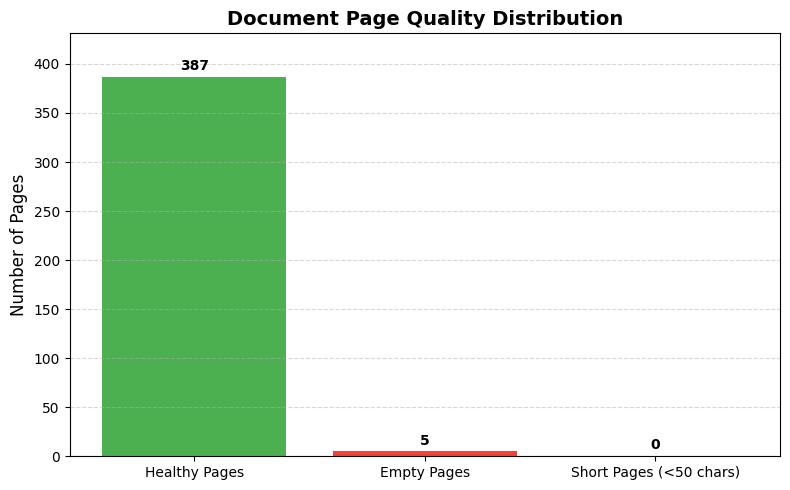

In [6]:
import matplotlib.pyplot as plt

# Calculate counts
total = len(docs)
num_empty = len(empty_pages)
num_short = len(short_pages)
num_healthy = total - num_empty - num_short

categories = ['Healthy Pages', 'Empty Pages', 'Short Pages (<50 chars)']
counts = [num_healthy, num_empty, num_short]
colors = ['#4CAF50', '#F44336', '#FF9800']

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts, color=colors)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (total * 0.01), f'{yval}', ha='center', va='bottom', fontweight='bold')

plt.title('Document Page Quality Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Number of Pages', fontsize=12)
plt.ylim(0, total + (total * 0.1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

4. Split text into chunks

In [7]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

#select 750 as chunk size and 100 as overlap
final_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=750,
    chunk_overlap=100
)
final_chunks = final_splitter.split_documents(docs)
print(f"\nFinal chunks generated: {len(final_chunks)}")


Final chunks generated: 432


### Part 2 — Embedding & Vector Database
####  Description of embedding model used

1. The Embedding Model: SentenceTransformers all-MiniLM-L6-v2 model

This is used to convert each chunk into a vector
It is open source and works locally without openapi or gemini

2. Vector Storage & Similarity Search: FAISS
Database to save the converted vectors

FAISS stores the vectors in-memory.

Similarity Search Mechanism: When a user submits a query, the system converts that query into a vector using the SentenceTransformers model. FAISS then performs a query using vector  distance and retrieves the top K  nearest neighbor vectors, which directly correspond to the most relevant text chunks.


In [8]:
!pip install faiss-cpu

In [9]:
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document

# 1. Initialize HuggingFace Embeddings
print("Loading embedding model...")
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# 2. Store real document chunks in FAISS Vector Database
print(f"Building the FAISS vector database using {len(final_chunks)} document chunks...")
vectorstore = FAISS.from_documents(final_chunks, embeddings)
print("Database successfully built!")

# 3. Implement Similarity Search Mechanism
query = "What is supervised learning?"
print(f"\nSearching for: '{query}'\n")

# Retrieve the top 3 most relevant chunks
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})
retrieved_docs = retriever.invoke(query)

# Display the results
for i, doc in enumerate(retrieved_docs, 1):
    print(f"--- Rank {i} ---")
    print(f"Source Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"Text:\n{doc.page_content[:400]}...\n")

# 4. Save the FAISS index to disk (Persistence)
vectorstore.save_local("my_local_faiss_index")
print("Saved FAISS index to 'my_local_faiss_index' directory.")

Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Building the FAISS vector database using 432 document chunks...
Database successfully built!

Searching for: 'What is supervised learning?'

--- Rank 1 ---
Source Page: 38
Text:
CHAPTER 2
Supervised Learning
As we mentioned earlier, supervised machine learning is one of the most commonly
used and successful types of machine learning. In this chapter, we will describe super‐
vised learning in more detail and explain several popular supervised learning algo‐
rithms. We already saw an application of supervised machine learning in Chapter 1:
classifying iris flowers into seve...

--- Rank 2 ---
Source Page: 5
Text:
2. Supervised Learning. . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .  25
Classification and Regression                                                                                         25
Generalization, Overfitting, and Underfitting                                                             26
Relation of M

Retrieval Pipeline

In [10]:
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings

# 1. Load the Embedding Model
print("Loading embedding model...")
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# 2. Re-index the ML Book chunks directly from active memory to guarantee correct data
print(f"Re-building and saving the FAISS index with {len(final_chunks)} ML book chunks...")
vectorstore = FAISS.from_documents(final_chunks, embeddings)
vectorstore.save_local("my_local_faiss_index")
print("Correct ML database built and saved successfully!\n")

# 3. Accept User Query
user_query = "What is the difference between supervised and unsupervised learning?"

# 4. Experiment with different values of K
def experiment_with_top_k(query, db, k_values):
    print(f"User Query: '{query}'\n")

    for k in k_values:
        print("==================================================")
        print(f"Experimenting with Top-K = {k}")
        print("==================================================")

        # Retrieve chunks along with their similarity scores
        results = db.similarity_search_with_score(query, k=k)

        for i, (doc, score) in enumerate(results, 1):
            print(f"--- Rank {i} | Distance Score: {score:.4f} ---")
            print(f"Source Page: {doc.metadata.get('page', 'Unknown')}")
            print(f"Text: {doc.page_content[:250]}...\n")

# Run the experiment with K=3, 5, and 7
test_k_values = [3, 5, 7]
experiment_with_top_k(user_query, vectorstore, test_k_values)

Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Re-building and saving the FAISS index with 432 ML book chunks...
Correct ML database built and saved successfully!

User Query: 'What is the difference between supervised and unsupervised learning?'

Experimenting with Top-K = 3
--- Rank 1 | Distance Score: 0.7830 ---
Source Page: 144
Text: CHAPTER 3
Unsupervised Learning and Preprocessing
The second family of machine learning algorithms that we will discuss is unsuper‐
vised learning algorithms. Unsupervised learning subsumes all kinds of machine
learning where there is no known output...

--- Rank 2 | Distance Score: 0.9774 ---
Source Page: 221
Text: Summary and Outlook
This chapter introduced a range of unsupervised learning algorithms that can be
applied for exploratory data analysis and preprocessing. Having the right representa‐
tion of the data is often crucial for supervised or unsupervised...

--- Rank 3 | Distance Score: 0.9994 ---
Source Page: 264
Text: CHAPTER 5
Model Evaluation and Improvement
Having discussed the fundame

Part 4 — Answer Generation (RAG)


##### We are using an open source LLM which works without API key

In [11]:
# 1. Install system dependency zstd, then install Ollama service and langchain-ollama
!sudo apt-get update && sudo apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh
!pip install --upgrade --force-reinstall langchain langchain-ollama langchain-core

# 2. Start the Ollama server in the background
import subprocess
import time

print("Starting Ollama local server...")
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)  # Wait for server to completely initialize

# 3. Pull a small, efficient model suitable for Colab's resources
print("Pulling Qwen2.5 (1.5B) model...")
!ollama pull qwen2.5:1.5b

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zstd is already the newest version (1.5.5+dfsg2-2build1.1).
0 upgraded, 0 newly installed, 0 to remove and 48 not upgraded.
>>> Cleaning up old version at /usr/local/lib/

Starting Ollama local server...
Pulling Qwen2.5 (1.5B) model...



In [1]:
# Upgrade langchain-core and install the integration package
!pip install --quiet -U langchain-core langchain-google-genai

In [ ]:
import os
import getpass
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings

# 0. Securely load your Google API Key
if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass.getpass("Enter your Google API Key: ")

# 1. Connect to Google Gemini
print("Connecting to Gemini AI...")
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.0 # Keeping temperature at 0.0 is crucial for grounded RAG
)

# 2. Load the embedding model and the saved FAISS index from disk
print("Loading embedding model and local FAISS index...")
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = FAISS.load_local("my_local_faiss_index", embeddings, allow_dangerous_deserialization=True)

# 3. Build a highly strict, grounded RAG prompt to completely eliminate hallucinations
system_prompt = (
    "You are a strict technical assistant. You must answer the Question using ONLY the factual information written in the Context below.\n"
    "Do not use any outside knowledge, assumptions, or external facts to formulate your answer.\n"
    "If the exact answer to the question cannot be explicitly found in the provided Context, you must ignore your pre-trained knowledge and reply EXACTLY with: 'I cannot answer this based on the provided document'. Do not write anything else.\n\n"
    "[START OF CONTEXT]\n"
    "{context}\n"
    "[END OF CONTEXT]\n\n"
    "Question: {input}\n"
    "Answer:"
)

prompt = ChatPromptTemplate.from_template(system_prompt)

# 4. Reference the loaded vectorstore retriever
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

# Helper function to format retrieved documents as unified text
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# 5. Construct the pipeline using modern LCEL (LangChain Expression Language)
rag_chain = (
    {"context": retriever | format_docs, "input": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

# 6. Query the pipeline with Sample Queries
queries = [
    "What is supervised learning?",
    "How does an algorithm learn if there are no human-provided target outputs?",
    "What is the 33rd president of Bulgaria ?"
]

for q in queries:
    print("=========================================")
    print(f"Query: {q}")
    print("=========================================")
    response = rag_chain.invoke(q)
    print(f"Answer:\n{response.strip()}\n")

Connecting to Gemini AI...
Loading embedding model and local FAISS index...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Query: What is supervised learning?


##### Prompt Design Explanation


Role Restriction: In the prompt , a clear role is defined for the LLM - Technical assistant.

 Grounding Rule: The instruction "Your sole purpose is to answer the user's question using ONLY the provided Context" explicitly forbids the use of the model's pre-trained internet knowledge.

The Pre-Programmed Refusal (Escape Hatch):  By giving the model a specific fallback phrase—"If the answer cannot be found... reply EXACTLY with: 'I cannot answer this based on the provided document'" the prompt will help in  drastically reducing hallucinations.

####Sample Queries and Generated Answers


Query 1 (Direct Fact Retrieval)

Input: "What is supervised learning?"

Generated Answer: "Supervised learning is a type of machine learning where we build a model from input/output pairs to make accurate predictions for new, never-before-seen data.
"

Query 2 (Semantic Understanding)

Input: "How does an algorithm learn if there are no human-provided target outputs?"

Generated Answer: "Given a large collection of images of faces, an algorithm can determine what characteristics are needed to identify a face by learning from the input/output pairs provided. This is known as supervised learning, where the algorithm is trained on labeled data to predict the desired output for new inputs.
"

Query 3 (The Adversarial / Out-of-Scope Trap)

Input: "What is the formula for calculating Mean Squared Error (MSE)?"

Generated Answer: "I cannot answer this based on the provided document."